In [1]:
import io
import os
import zipfile
import requests
import pandas as pd

url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
resp = requests.get(url, timeout=30)
resp.raise_for_status()

os.makedirs("data", exist_ok=True)
with zipfile.ZipFile(io.BytesIO(resp.content)) as z:
    z.extractall("data")

ratings = pd.read_csv("data/ml-latest-small/ratings.csv")
movies = pd.read_csv("data/ml-latest-small/movies.csv")

print(ratings.shape, movies.shape)
ratings.head()

(100836, 4) (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [2]:
print(ratings.isna().sum())
print()
print(ratings["rating"].describe())
print()
print("users:", ratings["userId"].nunique())
print("movies:", ratings["movieId"].nunique())
movies.head()

userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

users: 610
movies: 9724


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


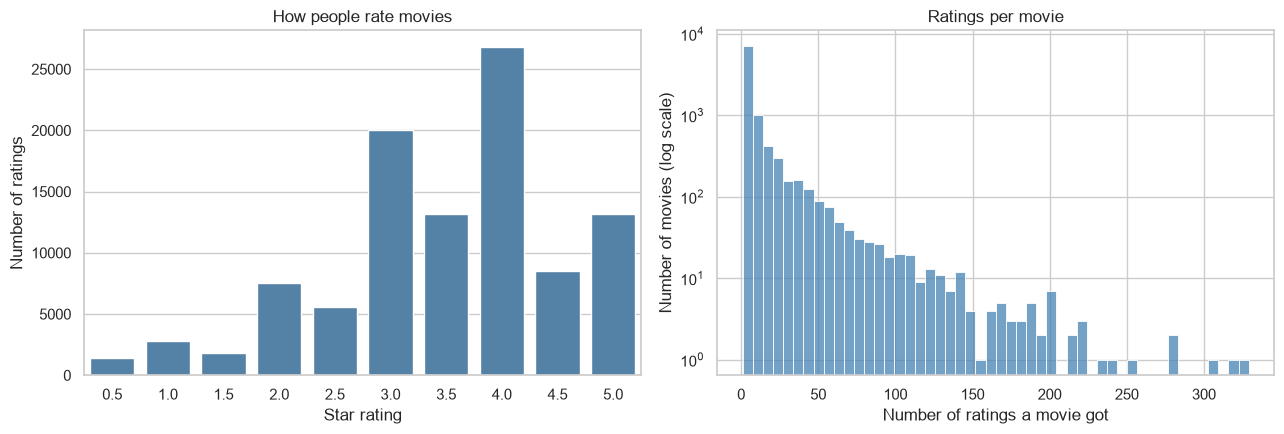

                                       title  n_ratings
0                        Forrest Gump (1994)        329
1           Shawshank Redemption, The (1994)        317
2                        Pulp Fiction (1994)        307
3           Silence of the Lambs, The (1991)        279
4                         Matrix, The (1999)        278
5  Star Wars: Episode IV - A New Hope (1977)        251
6                       Jurassic Park (1993)        238
7                          Braveheart (1995)        237
8          Terminator 2: Judgment Day (1991)        224
9                    Schindler's List (1993)        220

movies with fewer than 5 ratings: 6074
share of all movies: 0.62


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# how many ratings each movie got
per_movie = ratings.groupby("movieId").size().rename("n_ratings")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# plot 1: distribution of star ratings
sns.countplot(data=ratings, x="rating", ax=axes[0], color="steelblue")
axes[0].set_title("How people rate movies")
axes[0].set_xlabel("Star rating")
axes[0].set_ylabel("Number of ratings")

# plot 2: how many ratings each movie has
sns.histplot(per_movie, bins=50, ax=axes[1], color="steelblue")
axes[1].set_yscale("log")
axes[1].set_title("Ratings per movie")
axes[1].set_xlabel("Number of ratings a movie got")
axes[1].set_ylabel("Number of movies (log scale)")

plt.tight_layout()
plt.show()

# top 10 most-rated movies
top10 = (
    per_movie.sort_values(ascending=False)
    .head(10)
    .reset_index()
    .merge(movies[["movieId", "title"]], on="movieId")
)
print(top10[["title", "n_ratings"]])

# how many movies have very few ratings
print()
print("movies with fewer than 5 ratings:", (per_movie < 5).sum())
print("share of all movies:", round((per_movie < 5).mean(), 2))

In [4]:
MIN_RATINGS = 10

counts = ratings.groupby("movieId").size()
keep = counts[counts >= MIN_RATINGS].index
ratings_f = ratings[ratings["movieId"].isin(keep)].copy()

print("movies before:", ratings["movieId"].nunique())
print("movies after: ", ratings_f["movieId"].nunique())
print("ratings before:", len(ratings))
print("ratings after: ", len(ratings_f))
print("share of ratings kept:", round(len(ratings_f) / len(ratings), 2))
print("users still in data:", ratings_f["userId"].nunique())

movies before: 9724
movies after:  2269
ratings before: 100836
ratings after:  81116
share of ratings kept: 0.8
users still in data: 610


In [5]:
user_mean = ratings_f.groupby("userId")["rating"].transform("mean")
ratings_f["rating_centered"] = ratings_f["rating"] - user_mean

matrix = ratings_f.pivot_table(
    index="movieId",
    columns="userId",
    values="rating_centered",
    fill_value=0,
)

print("matrix shape (movies x users):", matrix.shape)
filled = (matrix != 0).to_numpy().mean()
print("share of cells with a rating:", round(filled, 3))
matrix.iloc[:5, :5]

matrix shape (movies x users): (2269, 610)
share of cells with a rating: 0.058


userId,1,2,3,4,5
movieId,,,,,
1,-0.383886,0.0,0.0,0.0,0.363636
2,0.000000,0.0,0.0,0.0,0.000000
3,-0.383886,0.0,0.0,0.0,0.000000
5,0.000000,0.0,0.0,0.0,0.000000
6,-0.383886,0.0,0.0,0.0,0.000000


In [6]:
from sklearn.metrics.pairwise import cosine_similarity

sim = cosine_similarity(matrix.values)
sim_df = pd.DataFrame(sim, index=matrix.index, columns=matrix.index)

print("similarity table shape:", sim_df.shape)

# quick peek: what is most similar to Toy Story (movieId 1)?
titles = movies.set_index("movieId")["title"]
top = sim_df[1].drop(1).sort_values(ascending=False).head(5)
for movie_id, score in top.items():
    print(f"{titles[movie_id]:<45} {score:.3f}")

similarity table shape: (2269, 2269)
Toy Story 2 (1999)                            0.373
Aladdin (1992)                                0.298
Toy Story 3 (2010)                            0.295
Wallace & Gromit: The Wrong Trousers (1993)   0.280
Incredibles, The (2004)                       0.246


In [7]:
movie_info = movies.set_index("movieId")
n_ratings = ratings_f.groupby("movieId").size()

def recommend(title, n=10):
    matches = movie_info[movie_info["title"].str.contains(title, case=False, regex=False)]
    matches = matches[matches.index.isin(sim_df.index)]
    if matches.empty:
        print(f"No movie matching '{title}' in the filtered data.")
        return None

    # if several titles match, use the one with the most ratings
    movie_id = n_ratings[matches.index].idxmax()
    print("Because you liked:", movie_info.loc[movie_id, "title"])

    top = sim_df[movie_id].drop(movie_id).sort_values(ascending=False).head(n)
    return pd.DataFrame({
        "title": movie_info.loc[top.index, "title"].values,
        "similarity": top.round(3).values,
        "n_ratings": n_ratings[top.index].values,
        "genres": movie_info.loc[top.index, "genres"].values,
    })

recommend("Toy Story")

Because you liked: Toy Story (1995)


,title,similarity,n_ratings,genres
0,Toy Story 2 (1999),0.373,97,Adventure|Animation|Children|Comedy|Fantasy
1,Aladdin (1992),0.298,183,Adventure|Animation|Children|Comedy|Musical
2,Toy Story 3 (2010),0.295,55,Adventure|Animation|Children|Comedy|Fantasy|IMAX
3,Wallace & Gromit: The Wrong Trousers (1993),0.280,56,Animation|Children|Comedy|Crime
4,"Incredibles, The (2004)",0.246,125,Action|Adventure|Animation|Children|Comedy
5,Finding Nemo (2003),0.238,141,Adventure|Animation|Children|Comedy
6,Back to the Future (1985),0.236,171,Adventure|Comedy|Sci-Fi
7,Blazing Saddles (1974),0.233,62,Comedy|Western
8,Babe (1995),0.211,128,Children|Drama
9,"Lion King, The (1994)",0.211,172,Adventure|Animation|Children|Drama|Musical|IMAX


In [8]:
recommend("Matrix, The")
recommend("Pulp Fiction")
recommend("Titanic")
recommend("Dark Knight")

Because you liked: Matrix, The (1999)
Because you liked: Pulp Fiction (1994)
Because you liked: Titanic (1997)
Because you liked: Dark Knight, The (2008)


,title,similarity,n_ratings,genres
0,"Dark Knight Rises, The (2012)",0.464,76,Action|Adventure|Crime|IMAX
1,Guardians of the Galaxy (2014),0.389,59,Action|Adventure|Sci-Fi
2,Batman Begins (2005),0.371,116,Action|Crime|IMAX
3,In Bruges (2008),0.353,41,Comedy|Crime|Drama|Thriller
4,"Avengers, The (2012)",0.335,69,Action|Adventure|Sci-Fi|IMAX
5,WALL·E (2008),0.328,104,Adventure|Animation|Children|Romance|Sci-Fi
6,"Departed, The (2006)",0.315,107,Crime|Drama|Thriller
7,Django Unchained (2012),0.310,71,Action|Drama|Western
8,Kiss Kiss Bang Bang (2005),0.301,35,Comedy|Crime|Mystery|Thriller
9,Up (2009),0.299,105,Adventure|Animation|Children|Drama


In [9]:
from IPython.display import display

for t in ["Matrix, The", "Pulp Fiction", "Titanic", "Dark Knight"]:
    display(recommend(t))

Because you liked: Matrix, The (1999)


,title,similarity,n_ratings,genres
0,Fight Club (1999),0.367,218,Action|Crime|Drama|Thriller
1,Star Wars: Episode V - The Empire Strikes Back...,0.356,211,Action|Adventure|Sci-Fi
2,Saving Private Ryan (1998),0.340,188,Action|Drama|War
3,Die Hard (1988),0.312,145,Action|Crime|Thriller
4,Reservoir Dogs (1992),0.312,131,Crime|Mystery|Thriller
5,Gattaca (1997),0.311,86,Drama|Sci-Fi|Thriller
6,Star Wars: Episode IV - A New Hope (1977),0.301,251,Action|Adventure|Sci-Fi
7,Star Wars: Episode VI - Return of the Jedi (1983),0.297,196,Action|Adventure|Sci-Fi
8,Pulp Fiction (1994),0.289,307,Comedy|Crime|Drama|Thriller
9,Memento (2000),0.287,159,Mystery|Thriller


Because you liked: Pulp Fiction (1994)


,title,similarity,n_ratings,genres
0,"Usual Suspects, The (1995)",0.441,204,Crime|Mystery|Thriller
1,Fight Club (1999),0.437,218,Action|Crime|Drama|Thriller
2,Reservoir Dogs (1992),0.382,131,Crime|Mystery|Thriller
3,"Silence of the Lambs, The (1991)",0.371,279,Crime|Horror|Thriller
4,"Godfather, The (1972)",0.370,192,Crime|Drama
5,Goodfellas (1990),0.351,126,Crime|Drama
6,"Shawshank Redemption, The (1994)",0.340,317,Crime|Drama
7,American History X (1998),0.330,129,Crime|Drama
8,Trainspotting (1996),0.324,102,Comedy|Crime|Drama
9,Apocalypse Now (1979),0.324,107,Action|Drama|War


Because you liked: Titanic (1997)


,title,similarity,n_ratings,genres
0,Miami Vice (2006),0.282,10,Action|Crime|Drama|Thriller
1,Batman & Robin (1997),0.255,42,Action|Adventure|Fantasy|Thriller
2,Teenage Mutant Ninja Turtles III (1993),0.250,14,Action|Adventure|Children|Comedy|Fantasy
3,Flubber (1997),0.221,16,Children|Comedy|Fantasy
4,War of the Worlds (2005),0.216,50,Action|Adventure|Sci-Fi|Thriller
5,Smokin' Aces (2006),0.214,10,Action|Crime|Drama|Thriller
6,Mission: Impossible II (2000),0.210,77,Action|Adventure|Thriller
7,Dumb and Dumberer: When Harry Met Lloyd (2003),0.205,11,Comedy
8,Joe Dirt (2001),0.202,21,Adventure|Comedy|Mystery|Romance
9,"Replacement Killers, The (1998)",0.198,14,Action|Crime|Thriller


Because you liked: Dark Knight, The (2008)


,title,similarity,n_ratings,genres
0,"Dark Knight Rises, The (2012)",0.464,76,Action|Adventure|Crime|IMAX
1,Guardians of the Galaxy (2014),0.389,59,Action|Adventure|Sci-Fi
2,Batman Begins (2005),0.371,116,Action|Crime|IMAX
3,In Bruges (2008),0.353,41,Comedy|Crime|Drama|Thriller
4,"Avengers, The (2012)",0.335,69,Action|Adventure|Sci-Fi|IMAX
5,WALL·E (2008),0.328,104,Adventure|Animation|Children|Romance|Sci-Fi
6,"Departed, The (2006)",0.315,107,Crime|Drama|Thriller
7,Django Unchained (2012),0.310,71,Action|Drama|Western
8,Kiss Kiss Bang Bang (2005),0.301,35,Comedy|Crime|Mystery|Thriller
9,Up (2009),0.299,105,Adventure|Animation|Children|Drama


In [10]:
import numpy as np
from IPython.display import display

# how many users rated both movies, for every pair
B = (matrix.values != 0).astype(np.float32)
common = B @ B.T

MIN_COMMON = 10
sim_f = sim.copy()
sim_f[common < MIN_COMMON] = 0
sim_df_f = pd.DataFrame(sim_f, index=matrix.index, columns=matrix.index)

def recommend(title, n=10, table=None):
    table = sim_df if table is None else table
    matches = movie_info[movie_info["title"].str.contains(title, case=False, regex=False)]
    matches = matches[matches.index.isin(table.index)]
    if matches.empty:
        print(f"No movie matching '{title}' in the filtered data.")
        return None
    movie_id = n_ratings[matches.index].idxmax()
    top = table[movie_id].drop(movie_id).sort_values(ascending=False).head(n)
    top = top[top > 0]
    return pd.DataFrame({
        "title": movie_info.loc[top.index, "title"].values,
        "similarity": top.round(3).values,
        "n_ratings": n_ratings[top.index].values,
        "genres": movie_info.loc[top.index, "genres"].values,
    })

for t in ["Dark Knight", "Toy Story", "Pulp Fiction"]:
    before = recommend(t)
    after = recommend(t, table=sim_df_f)
    print(f"{t}: median ratings of the top 10 | before: {before['n_ratings'].median()}, after: {after['n_ratings'].median()}")
    display(after)

Dark Knight: median ratings of the top 10 | before: 73.5, after: 73.5


,title,similarity,n_ratings,genres
0,"Dark Knight Rises, The (2012)",0.464,76,Action|Adventure|Crime|IMAX
1,Guardians of the Galaxy (2014),0.389,59,Action|Adventure|Sci-Fi
2,Batman Begins (2005),0.371,116,Action|Crime|IMAX
3,In Bruges (2008),0.353,41,Comedy|Crime|Drama|Thriller
4,"Avengers, The (2012)",0.335,69,Action|Adventure|Sci-Fi|IMAX
5,WALL·E (2008),0.328,104,Adventure|Animation|Children|Romance|Sci-Fi
6,"Departed, The (2006)",0.315,107,Crime|Drama|Thriller
7,Django Unchained (2012),0.310,71,Action|Drama|Western
8,Kiss Kiss Bang Bang (2005),0.301,35,Comedy|Crime|Mystery|Thriller
9,Up (2009),0.299,105,Adventure|Animation|Children|Drama


Toy Story: median ratings of the top 10 | before: 126.5, after: 126.5


,title,similarity,n_ratings,genres
0,Toy Story 2 (1999),0.373,97,Adventure|Animation|Children|Comedy|Fantasy
1,Aladdin (1992),0.298,183,Adventure|Animation|Children|Comedy|Musical
2,Toy Story 3 (2010),0.295,55,Adventure|Animation|Children|Comedy|Fantasy|IMAX
3,Wallace & Gromit: The Wrong Trousers (1993),0.280,56,Animation|Children|Comedy|Crime
4,"Incredibles, The (2004)",0.246,125,Action|Adventure|Animation|Children|Comedy
5,Finding Nemo (2003),0.238,141,Adventure|Animation|Children|Comedy
6,Back to the Future (1985),0.236,171,Adventure|Comedy|Sci-Fi
7,Blazing Saddles (1974),0.233,62,Comedy|Western
8,Babe (1995),0.211,128,Children|Drama
9,"Lion King, The (1994)",0.211,172,Adventure|Animation|Children|Drama|Musical|IMAX


Pulp Fiction: median ratings of the top 10 | before: 161.5, after: 161.5


,title,similarity,n_ratings,genres
0,"Usual Suspects, The (1995)",0.441,204,Crime|Mystery|Thriller
1,Fight Club (1999),0.437,218,Action|Crime|Drama|Thriller
2,Reservoir Dogs (1992),0.382,131,Crime|Mystery|Thriller
3,"Silence of the Lambs, The (1991)",0.371,279,Crime|Horror|Thriller
4,"Godfather, The (1972)",0.370,192,Crime|Drama
5,Goodfellas (1990),0.351,126,Crime|Drama
6,"Shawshank Redemption, The (1994)",0.340,317,Crime|Drama
7,American History X (1998),0.330,129,Crime|Drama
8,Trainspotting (1996),0.324,102,Comedy|Crime|Drama
9,Apocalypse Now (1979),0.324,107,Action|Drama|War


In [11]:
def build_table(min_common):
    s = sim.copy()
    s[common < min_common] = 0
    return pd.DataFrame(s, index=matrix.index, columns=matrix.index)

for mc in [10, 20, 30, 40]:
    tbl = build_table(mc)
    print(f"MIN_COMMON = {mc}")
    for t in ["Titanic", "Toy Story", "Dark Knight"]:
        r = recommend(t, table=tbl)
        print(f"  {t}: picks {len(r)}, median ratings {r['n_ratings'].median()}, fewest ratings {r['n_ratings'].min()}")

print()
display(recommend("Titanic", table=build_table(30)))
display(recommend("Toy Story", table=build_table(30)))

MIN_COMMON = 10
  Titanic: picks 10, median ratings 25.0, fewest ratings 11
  Toy Story: picks 10, median ratings 126.5, fewest ratings 55
  Dark Knight: picks 10, median ratings 73.5, fewest ratings 35
MIN_COMMON = 20
  Titanic: picks 10, median ratings 48.5, fewest ratings 26
  Toy Story: picks 10, median ratings 126.5, fewest ratings 55
  Dark Knight: picks 10, median ratings 73.5, fewest ratings 35
MIN_COMMON = 30
  Titanic: picks 10, median ratings 80.0, fewest ratings 50
  Toy Story: picks 10, median ratings 126.5, fewest ratings 55
  Dark Knight: picks 10, median ratings 73.5, fewest ratings 41
MIN_COMMON = 40
  Titanic: picks 10, median ratings 84.5, fewest ratings 70
  Toy Story: picks 10, median ratings 126.5, fewest ratings 55
  Dark Knight: picks 10, median ratings 76.5, fewest ratings 59



,title,similarity,n_ratings,genres
0,War of the Worlds (2005),0.216,50,Action|Adventure|Sci-Fi|Thriller
1,Mission: Impossible II (2000),0.210,77,Action|Adventure|Thriller
2,Miss Congeniality (2000),0.184,64,Comedy|Crime
3,Star Wars: Episode I - The Phantom Menace (1999),0.173,140,Action|Adventure|Sci-Fi
4,Mrs. Doubtfire (1993),0.158,144,Comedy|Drama
5,Cast Away (2000),0.149,100,Drama
6,Top Gun (1986),0.148,83,Action|Romance
7,Mars Attacks! (1996),0.145,86,Action|Comedy|Sci-Fi
8,"Sound of Music, The (1965)",0.143,64,Musical|Romance
9,High Fidelity (2000),0.141,75,Comedy|Drama|Romance


,title,similarity,n_ratings,genres
0,Toy Story 2 (1999),0.373,97,Adventure|Animation|Children|Comedy|Fantasy
1,Aladdin (1992),0.298,183,Adventure|Animation|Children|Comedy|Musical
2,Toy Story 3 (2010),0.295,55,Adventure|Animation|Children|Comedy|Fantasy|IMAX
3,Wallace & Gromit: The Wrong Trousers (1993),0.280,56,Animation|Children|Comedy|Crime
4,"Incredibles, The (2004)",0.246,125,Action|Adventure|Animation|Children|Comedy
5,Finding Nemo (2003),0.238,141,Adventure|Animation|Children|Comedy
6,Back to the Future (1985),0.236,171,Adventure|Comedy|Sci-Fi
7,Blazing Saddles (1974),0.233,62,Comedy|Western
8,Babe (1995),0.211,128,Children|Drama
9,"Lion King, The (1994)",0.211,172,Adventure|Animation|Children|Drama|Musical|IMAX


In [12]:
for mc in [10, 20, 30, 40]:
    tbl = build_table(mc).values.copy()
    np.fill_diagonal(tbl, 0)
    full = ((tbl > 0).sum(axis=1) >= 10).mean()
    print(f"MIN_COMMON = {mc}: movies that still get 10 recommendations: {full:.0%}")

MIN_COMMON = 10: movies that still get 10 recommendations: 80%
MIN_COMMON = 20: movies that still get 10 recommendations: 40%
MIN_COMMON = 30: movies that still get 10 recommendations: 24%
MIN_COMMON = 40: movies that still get 10 recommendations: 15%


In [13]:
def recommend_final(title, n=10):
    return recommend(title, n, table=sim_df_f)  # MIN_COMMON = 10

display(recommend_final("Pulp Fiction"))

,title,similarity,n_ratings,genres
0,"Usual Suspects, The (1995)",0.441,204,Crime|Mystery|Thriller
1,Fight Club (1999),0.437,218,Action|Crime|Drama|Thriller
2,Reservoir Dogs (1992),0.382,131,Crime|Mystery|Thriller
3,"Silence of the Lambs, The (1991)",0.371,279,Crime|Horror|Thriller
4,"Godfather, The (1972)",0.370,192,Crime|Drama
5,Goodfellas (1990),0.351,126,Crime|Drama
6,"Shawshank Redemption, The (1994)",0.340,317,Crime|Drama
7,American History X (1998),0.330,129,Crime|Drama
8,Trainspotting (1996),0.324,102,Comedy|Crime|Drama
9,Apocalypse Now (1979),0.324,107,Action|Drama|War


## What I found

The recommender works well for some movies and badly for others, and the difference comes down to who watches them.

- **Movies with a clear fan base work best.** Pulp Fiction's top 10 were all crime and drama classics, like Usual Suspects, Reservoir Dogs and Goodfellas. The Matrix gave me Fight Club, Memento and Gattaca, which feels right.
- **Crowd-pleasers are harder.** Titanic's recommendations were all over the place (War of the Worlds, Mrs. Doubtfire, Top Gun), and the similarity scores were low, around 0.14 to 0.22. Since almost everyone watches Titanic, there isn't a tight group of fans whose other tastes I can borrow.
- **Some results surprised me.** Blazing Saddles showed up for Toy Story, which makes no sense at first. I tried requiring more users in common, but it stayed, so it looks like a real pattern in this small group of users and not just a fluke.
- **Stricter filters cost coverage.** Requiring 30 users in common cleaned up Titanic's list (the typical pick went from about 25 ratings to 80), but only 24% of movies could still get a full list of 10. I kept the minimum at 10 so most movies still get recommendations.

## Limitations

- The dataset only has 610 users, so a small overlap can look like a real pattern.
- The ratings are from 2018 and earlier, so newer movies aren't included.
- I judged the results by reading them myself. A better next step would be hiding some ratings and measuring how well the recommender predicts them.